# Market Regime Detection and Machine Learning-Driven Dynamic Asset Allocation

## Capstone Project

### Author
Ajay Singh Sisodia

### Overview

Traditional portfolio allocation methods rely heavily on historical market relationships and often assume that asset behavior remains relatively stable over time. However, financial markets transition through distinct environments characterized by changing levels of risk, volatility, and asset performance. This project investigates whether market regimes can be identified using machine learning techniques and whether regime-aware portfolio allocation can improve investment outcomes relative to a traditional static allocation approach.

### Research Question

Can market regime detection and machine learning-driven dynamic asset allocation improve risk-adjusted portfolio performance compared to traditional static asset allocation strategies?

### Project Objectives

- Identify distinct market regimes using machine learning techniques.
- Analyze asset behavior across different market environments.
- Develop a regime-aware portfolio allocation framework.
- Compare regime-aware portfolio performance against a traditional static portfolio.
- Evaluate whether market regime information can enhance investment decision-making.



## Project Roadmap

1. Data Collection and Preparation
2. Feature Engineering
3. Principal Component Analysis (PCA)
4. Model Selection and Validation
5. Market Regime Detection
6. Regime Analysis and Interpretation
7. Regime-Based Asset Performance Analysis
8. Regime-Aware Portfolio Construction
9. Portfolio Backtesting and Performance Evaluation
10. Results and Discussion
11. Limitations
12. Key Findings
13. Conclusion and Future Work

## 1. Data Collection and Preparation

This section loads the historical ETF data and prepares the dataset for analysis. The portfolio consists of six ETFs representing major asset classes including equities, fixed income, commodities, real estate, and credit markets.

### Assets Included

- SPY: U.S. Equities
- QQQ: Technology Equities
- TLT: Treasury Bonds
- GLD: Gold
- VNQ: Real Estate
- HYG: High Yield Bonds

The dataset covers the period from January 2015 through November 2026.


In [2]:
# Import Libraries
import pandas as pd
import numpy as np
import yfinance as yf

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

plt.style.use('default')

import warnings
warnings.filterwarnings('ignore')

In [3]:
#  Download Data 
tickers = ['SPY', 'QQQ', 'TLT', 'GLD', 'VNQ', 'HYG']

data = yf.download(
    tickers,
    start='2015-01-01',
    auto_adjust=True,
    progress=False,
    threads=False
)

prices = data['Close']

prices.head()

Ticker,GLD,HYG,QQQ,SPY,TLT,VNQ
Date,,,,,,
2015-01-02,114.080002,48.073109,94.462708,169.267517,91.935234,51.642845
2015-01-05,115.800003,47.627789,93.077042,166.210587,93.379387,51.925472
2015-01-06,117.120003,47.445358,91.829071,164.645035,95.061859,52.440514
2015-01-07,116.430000,47.740456,93.012848,166.696777,94.874077,53.244495
2015-01-08,115.940002,48.099934,94.793076,169.654816,93.617645,53.445496


In [4]:
print(f"Shape: {prices.shape}")
print()
print(prices.info())

Shape: (2978, 6)

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2978 entries, 2015-01-02 to 2026-11-04
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   GLD     2977 non-null   float64
 1   HYG     2977 non-null   float64
 2   QQQ     2977 non-null   float64
 3   SPY     2977 non-null   float64
 4   TLT     2977 non-null   float64
 5   VNQ     2977 non-null   float64
dtypes: float64(6)
memory usage: 162.9 KB
None


### Findings

The dataset contains daily adjusted closing prices for six ETFs spanning multiple market cycles. The selected assets provide broad exposure across different asset classes and offer a suitable foundation for market regime analysis and portfolio construction.

## 2. Feature Engineering

To support market regime detection, a set of features was engineered from the ETF price data. These features were designed to capture market trends, risk characteristics, and downside behavior across asset classes.

The engineered features include:

- 20-Day Momentum
- 50-Day Momentum
- 20-Day Rolling Volatility
- 50-Day Rolling Volatility
- Moving Average Ratio (20-Day / 50-Day)
- Drawdown

These features will serve as inputs for Principal Component Analysis (PCA) and market regime detection.

**A comprehensive analysis of this phase was previously executed during the Exploratory Data Analysis (EDA) stage.**

In [6]:
# Daily returns
returns = prices.pct_change().dropna()

In [7]:
# Momentum Features
momentum_20 = prices.pct_change(20)
momentum_20.columns = [f'{col}_mom20' for col in momentum_20.columns]

momentum_50 = prices.pct_change(50)
momentum_50.columns = [f'{col}_mom50' for col in momentum_50.columns]

In [8]:
# Volatility Features
volatility_20 = returns.rolling(20).std()
volatility_20.columns = [f'{col}_vol20' for col in volatility_20.columns]

volatility_50 = returns.rolling(50).std()
volatility_50.columns = [f'{col}_vol50' for col in volatility_50.columns]

In [9]:
# Trend Features
ma20 = prices.rolling(20).mean()
ma50 = prices.rolling(50).mean()

ma_ratio = ma20 / ma50
ma_ratio.columns = [f'{col}_ma_ratio' for col in ma_ratio.columns]

In [10]:
# Drawdown Features
cumulative_returns = (1 + returns).cumprod()

rolling_max = cumulative_returns.cummax()

drawdown = (cumulative_returns - rolling_max) / rolling_max

drawdown.columns = [f'{col}_drawdown' for col in drawdown.columns]

In [11]:
features = pd.concat([
    momentum_20,
    momentum_50,
    volatility_20,
    volatility_50,
    ma_ratio,
    drawdown
], axis=1)

features = features.dropna()

In [12]:
print(features.shape)
features.head()

(2927, 36)


,GLD_mom20,HYG_mom20,QQQ_mom20,SPY_mom20,TLT_mom20,VNQ_mom20,GLD_mom50,HYG_mom50,QQQ_mom50,SPY_mom50,...,QQQ_ma_ratio,SPY_ma_ratio,TLT_ma_ratio,VNQ_ma_ratio,GLD_drawdown,HYG_drawdown,QQQ_drawdown,SPY_drawdown,TLT_drawdown,VNQ_drawdown
Date,,,,,,,,,,,,,,,,,,,,,
2015-03-17,-0.049996,-0.011144,-0.001308,-0.010233,0.023693,-0.019446,-0.033924,0.009050,0.038178,0.012316,...,1.028008,1.015927,0.976461,0.977896,-0.119939,-0.019863,-0.022948,-0.019010,-0.063402,-0.061478
2015-03-18,-0.034124,-0.005707,0.007092,0.001570,0.037291,-0.008173,-0.029620,0.027572,0.063985,0.043328,...,1.027098,1.015145,0.977873,0.976962,-0.102691,-0.011118,-0.013348,-0.007217,-0.045324,-0.041850
2015-03-19,-0.031482,-0.011347,0.003622,-0.002286,0.038876,0.013127,-0.041240,0.023314,0.080044,0.048444,...,1.025716,1.014077,0.979800,0.977285,-0.103330,-0.018988,-0.011886,-0.011746,-0.050188,-0.042301
2015-03-20,-0.014833,-0.006361,0.003409,0.000517,0.041302,0.028602,-0.024564,0.024921,0.073200,0.044680,...,1.024444,1.013216,0.981706,0.978188,-0.093109,-0.011336,-0.005490,-0.003023,-0.045179,-0.018274
2015-03-23,-0.009876,-0.006353,0.000453,-0.001290,0.028253,0.019111,-0.014232,0.018048,0.051008,0.024465,...,1.023441,1.012656,0.982758,0.978725,-0.087359,-0.010571,-0.007413,-0.004965,-0.046340,-0.019515


### Feature Engineering Summary

A total of 36 engineered features were created across six ETFs. These features capture momentum, volatility, trend direction, and drawdown behavior, providing a comprehensive representation of market conditions. The resulting feature set will be used as the foundation for dimensionality reduction and market regime identification.

The dataset was refreshed at the time of modeling and therefore contains a slightly larger number of observations than the EDA dataset. The additional observations do not affect the feature engineering process or overall methodology.

## 3. Dimensionality Reduction Using Principal Component Analysis (PCA)

The engineered dataset contains 36 features representing momentum, volatility, trend, and drawdown characteristics across six asset classes. Many of these features are likely correlated and may contain redundant information. Principal Component Analysis (PCA) is applied to reduce dimensionality while retaining the majority of the information contained within the dataset.

The resulting principal components will be used as inputs for market regime detection.

### 3.1 Standardize Features

In [14]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

scaled_features = scaler.fit_transform(features)

scaled_features.shape

(2927, 36)

### 3.2 Fit PCA

In [15]:
from sklearn.decomposition import PCA

pca = PCA()

pca.fit(scaled_features)

,n_components,None
,copy,True
,whiten,False
,svd_solver,'auto'
,tol,0.0
,iterated_power,'auto'
,n_oversamples,10
,power_iteration_normalizer,'auto'
,random_state,None


### 3.3 Variance Plot

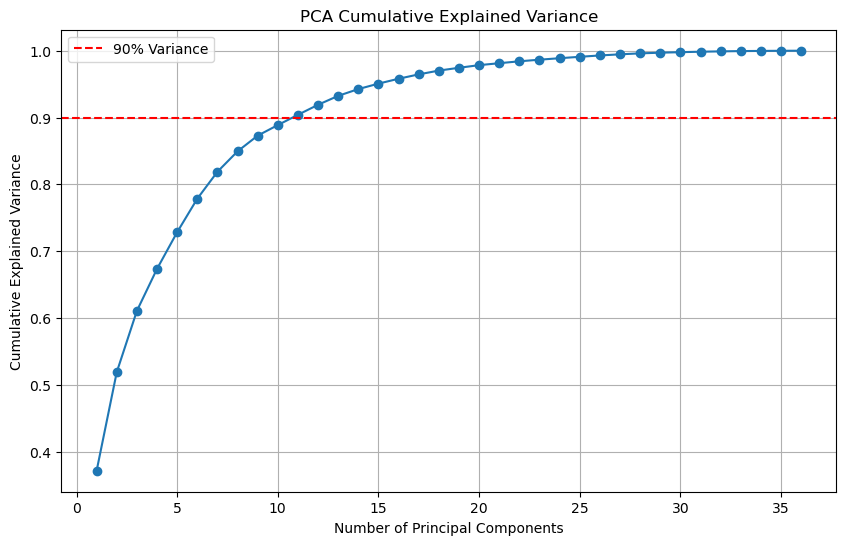

In [16]:
cumulative_variance = np.cumsum(
    pca.explained_variance_ratio_
)

plt.figure(figsize=(10,6))

plt.plot(
    range(1, len(cumulative_variance)+1),
    cumulative_variance,
    marker='o'
)

plt.axhline(
    y=0.90,
    color='red',
    linestyle='--',
    label='90% Variance'
)

plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('PCA Cumulative Explained Variance')
plt.legend()
plt.grid(True)

plt.show()

### 3.4 Determine Optimal Components

In [17]:
num_components = np.argmax(
    cumulative_variance >= 0.90
) + 1

print(f"Number of Components for 90% Variance: {num_components}")


Number of Components for 90% Variance: 11


### 3.5 Create PCA Dataset

In [20]:
pca = PCA(n_components=num_components)

pca_features = pca.fit_transform(
    scaled_features
)

print(pca_features.shape)

(2927, 11)


### PCA Findings

Principal Component Analysis (PCA) was applied to the 36 engineered features to reduce dimensionality and minimize redundancy among correlated variables. The cumulative explained variance analysis indicated that 11 principal components were sufficient to retain approximately 90% of the information contained in the original dataset. This represents a substantial reduction in dimensionality while preserving the majority of the dataset's variation. The reduced feature set will be used as input for market regime detection, helping improve clustering efficiency and interpretability.

## 4. Model Selection and Validation
### 4.1 Model Selection Approach
Market regime detection was performed using K-Means clustering, an unsupervised machine learning algorithm that groups observations based on similarities in their underlying characteristics. Because the optimal number of market regimes was unknown, multiple cluster configurations were evaluated.

The PCA-transformed dataset was used as input to the clustering model to reduce dimensionality, minimize redundancy among features, and improve clustering effectiveness.

The PCA-transformed feature set was used as input for K-Means clustering. To determine the optimal number of market regimes, multiple cluster configurations were evaluated using the Elbow Method and Silhouette Analysis.

### 4.2 Hyperparameter Tuning

The primary K-Means hyperparameter evaluated in this study was the number of clusters (K). To identify the optimal market regime structure, values of K ranging from 2 to 10 were evaluated using the Elbow Method and Silhouette Analysis.

**Determine Optimal Number of Clusters**

In [84]:
inertia = []

for k in range(2, 11):
    
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    kmeans.fit(pca_features)
    
    inertia.append(kmeans.inertia_)

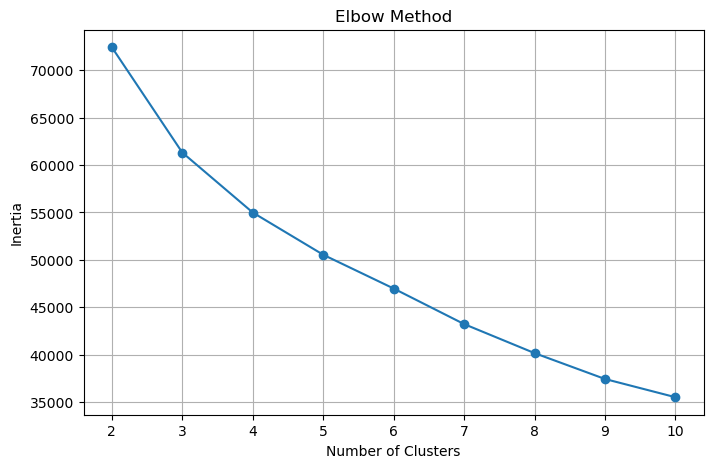

In [22]:
plt.figure(figsize=(8,5))

plt.plot(
    range(2,11),
    inertia,
    marker='o'
)

plt.title('Elbow Method')
plt.xlabel('Number of Clusters')
plt.ylabel('Inertia')

plt.grid(True)

plt.show()

In [85]:
silhouette_scores = []

for k in range(2,11):
    
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    labels = kmeans.fit_predict(pca_features)
    
    score = silhouette_score(pca_features,labels)
    
    silhouette_scores.append(score)

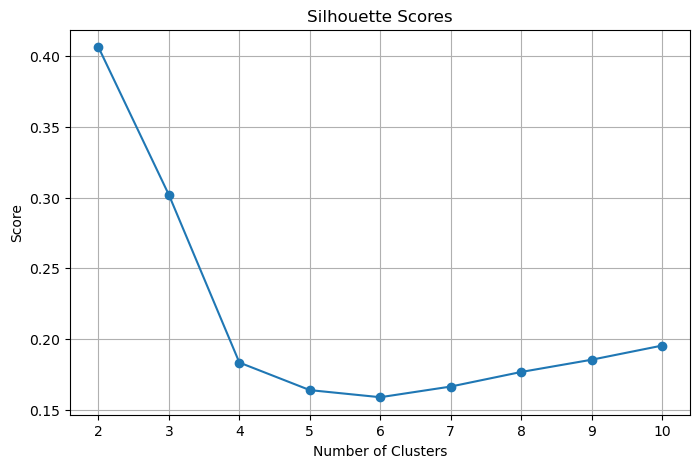

In [24]:
plt.figure(figsize=(8,5))

plt.plot(
    range(2,11),
    silhouette_scores,
    marker='o'
)

plt.title('Silhouette Scores')
plt.xlabel('Number of Clusters')
plt.ylabel('Score')

plt.grid(True)

plt.show()

In [25]:
best_k = np.argmax(
    silhouette_scores
) + 2

print(f"Best K: {best_k}")

Best K: 2


In [90]:
validation_results = pd.DataFrame({
    'K': range(2,11),
    'Silhouette Score': silhouette_scores,
    'Inertia': inertia
})

validation_results

,K,Silhouette Score,Inertia
0,2,0.406224,72444.577547
1,3,0.301839,61325.249182
2,4,0.183350,54993.715101
3,5,0.163869,50537.025373
4,6,0.158843,46970.753253
5,7,0.166388,43216.034811
6,8,0.176693,40151.450207
7,9,0.185347,37417.680023
8,10,0.195346,35494.469408


### Final Model Selection
The Elbow Method and Silhouette Analysis were used to determine the optimal number of clusters for market regime detection. The highest silhouette score ~ (0.4) was achieved with two clusters, indicating the strongest separation between groups. Consequently, a two-cluster solution was selected as the initial regime-detection framework for further analysis.

Although financial markets are often described using multiple regimes such as bull, bear, recovery, and crisis environments, silhouette analysis indicated that a two-cluster solution provided the strongest separation within the engineered feature space. Consequently, a two-regime framework was selected to maximize cluster quality and interpretability.

The final model provides a data-driven framework for identifying distinct market environments and serves as the foundation for subsequent regime analysis, portfolio construction, and performance evaluation.

## 5. Market Regime Detection

Market regime detection seeks to identify periods in which financial markets exhibit similar characteristics with respect to risk, volatility, momentum, and trend behavior. Since regime labels are not known in advance, an unsupervised learning approach is used.

K-Means clustering is applied to the PCA-transformed feature set to identify groups of observations that share similar market characteristics. These clusters will be interpreted as potential market regimes and analyzed further in subsequent sections.

### 5.1 Create Regime Dataset

In [27]:
kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

cluster_labels = kmeans.fit_predict(pca_features)

In [28]:
regime_data = pd.DataFrame(
    pca_features,
    index=features.index
)

regime_data['Regime'] = cluster_labels

regime_data.head()

,0,1,2,3,4,5,6,7,8,9,10,Regime
Date,,,,,,,,,,,,
2015-03-17,-0.395803,-1.537041,-1.143822,1.686518,0.152230,0.613271,0.991394,0.201114,-0.200371,0.019980,0.085253,0
2015-03-18,-0.791384,-0.795806,-1.025664,1.744613,0.476599,0.597519,1.194553,0.320392,0.503943,0.313425,0.270837,0
2015-03-19,-0.723666,-0.952422,-1.168574,1.760017,0.482580,0.541325,1.099825,0.400570,0.474562,0.372710,0.600538,0
2015-03-20,-0.844669,-0.567301,-0.783623,1.760719,0.784809,0.378374,1.042123,0.330471,0.670182,0.422938,0.728701,0
2015-03-23,-0.664909,-0.743663,-0.493026,1.616862,0.765972,0.301019,1.068051,0.231126,0.430231,0.387892,0.518609,0


In [29]:
regime_data['Regime'].value_counts()

Regime
0    2467
1     460
Name: count, dtype: int64

In [30]:
regime_data['Regime'].value_counts(normalize=True) * 100

Regime
0    84.28425
1    15.71575
Name: proportion, dtype: float64

In [31]:
returns_regime = returns.loc[regime_data.index].copy()

returns_regime['Regime'] = cluster_labels


### 5.2 First Regime Analysis 

In [32]:
regime_volatility = (
    returns_regime
    .groupby('Regime')
    .std()
)

regime_volatility


Ticker,GLD,HYG,QQQ,SPY,TLT,VNQ
Regime,,,,,,
0,0.009937,0.003405,0.011319,0.008290,0.007954,0.009732
1,0.011908,0.010209,0.023123,0.020205,0.014347,0.022774


In [33]:
regime_volatility.mean(axis=1)

Regime
0    0.008440
1    0.017094
dtype: float64

**Regime Distribution and Regime Volatility Comparison**

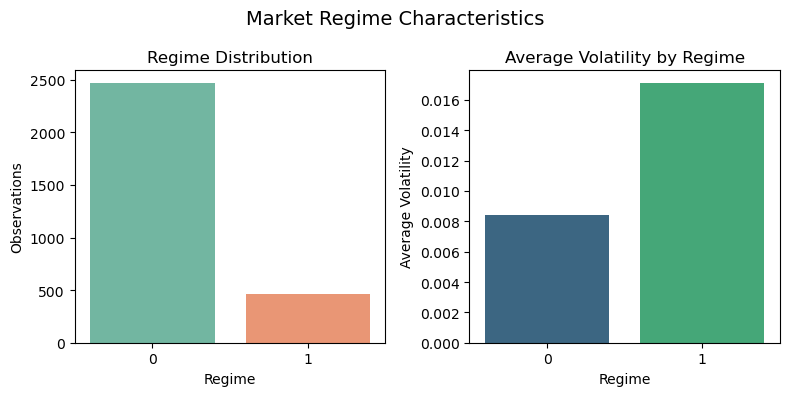

In [86]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(8,4)
)

# Regime Distribution
regime_counts = regime_data['Regime'].value_counts().sort_index()

sns.barplot(
    x=regime_counts.index,
    y=regime_counts.values,
    ax=axes[0],
    palette='Set2'
)

axes[0].set_title('Regime Distribution')
axes[0].set_xlabel('Regime')
axes[0].set_ylabel('Observations')

# Average Volatility
regime_vol_mean = regime_volatility.mean(axis=1)

sns.barplot(
    x=regime_vol_mean.index,
    y=regime_vol_mean.values,
    ax=axes[1],
    palette='viridis'
)

axes[1].set_title('Average Volatility by Regime')
axes[1].set_xlabel('Regime')
axes[1].set_ylabel('Average Volatility')

plt.suptitle(
    'Market Regime Characteristics',
    fontsize=14
)

plt.tight_layout()

plt.show()

**PCA Cluster Plot**

### Initial Regime Characteristics

The K-Means clustering algorithm identified two distinct market regimes within the PCA-transformed feature space. Regime 0 accounted for approximately 84% of observations and exhibited relatively low average volatility (0.84%), suggesting normal or stable market conditions. In contrast, Regime 1 represented approximately 16% of observations and displayed approximately double the average volatility (1.71%), indicating periods of elevated market uncertainty and risk.

The clear separation in volatility profiles suggests that the clustering algorithm successfully differentiated between normal market environments and higher-volatility stress periods. These results provide preliminary evidence that market behavior can be grouped into distinct regimes, supporting the use of regime-aware investment strategies. Further analysis of returns, drawdowns, and asset performance will be conducted to validate the economic significance of each regime.

### 5.3 Regime Timing Analysis

To evaluate the practical significance of the detected regimes, regime assignments were overlaid on the SPY price series. Periods classified as Regime 1 corresponded primarily to episodes of heightened market uncertainty and volatility, while Regime 0 dominated during relatively stable market conditions. This visual validation provides additional evidence that the clustering algorithm successfully identified economically meaningful market environments.

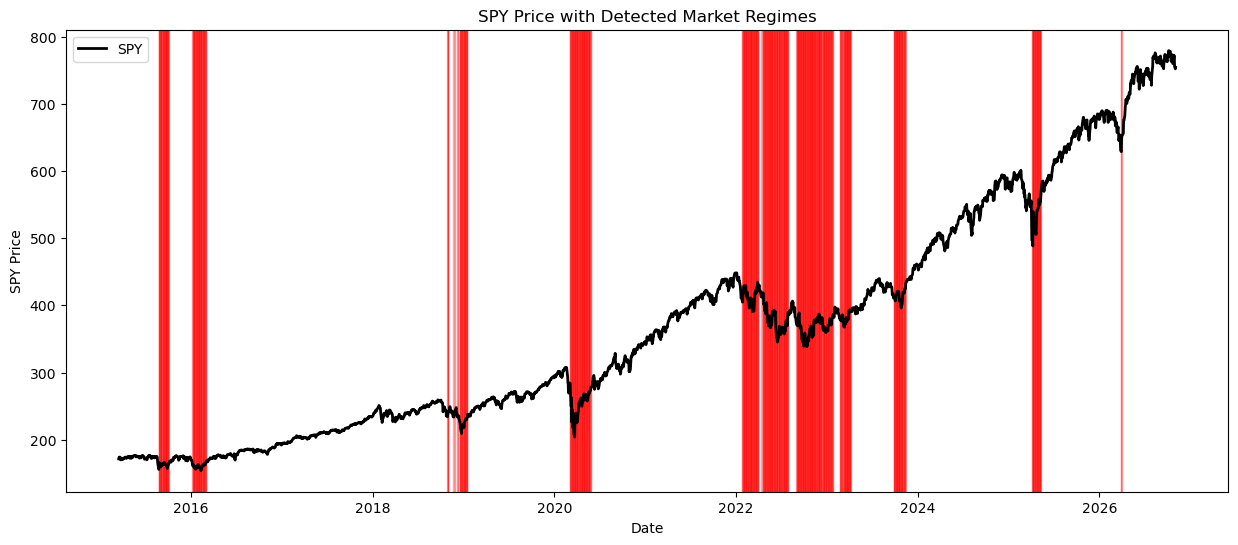

In [46]:
# Create regime series
regime_series = pd.Series(
    cluster_labels,
    index=features.index
)

spy_prices = prices.loc[features.index, 'SPY']

plt.figure(figsize=(15,6))

plt.plot(
    spy_prices.index,
    spy_prices,
    color='black',
    linewidth=2,
    label='SPY'
)

# Shade High-Volatility Regime
for i in range(len(regime_series)-1):

    if regime_series.iloc[i] == 1:

        plt.axvspan(
            regime_series.index[i],
            regime_series.index[i+1],
            color='red',
            alpha=0.3
        )

plt.title('SPY Price with Detected Market Regimes')
plt.xlabel('Date')
plt.ylabel('SPY Price')
plt.legend()

plt.show()

## 6. Regime Analysis and Interpretation

In [97]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

rf.fit(features, cluster_labels)

feature_importance = pd.DataFrame({
    'Feature': features.columns,
    'Importance': rf.feature_importances_
})

feature_importance = (
    feature_importance
    .sort_values(
        'Importance',
        ascending=False
    )
)

#feature_importance.head(10)

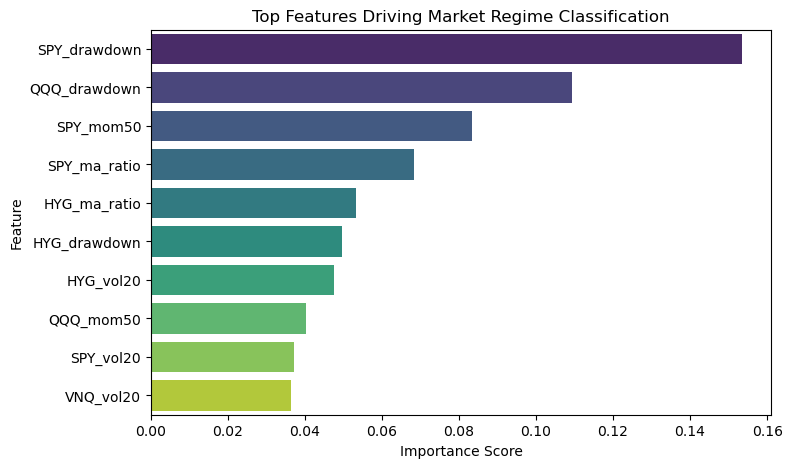

In [98]:
top_features = feature_importance.head(10)

plt.figure(figsize=(8,5))

sns.barplot(
    data=top_features,
    x='Importance',
    y='Feature',
    palette='viridis'
)

plt.title(
    'Top Features Driving Market Regime Classification'
)

plt.xlabel('Importance Score')
plt.ylabel('Feature')

plt.show()

###  Average Returns by Regime

In [47]:
regime_returns = (
    returns_regime
    .groupby('Regime')
    .mean()
)

regime_returns

Ticker,GLD,HYG,QQQ,SPY,TLT,VNQ
Regime,,,,,,
0,0.000346,0.000227,0.000905,0.000724,0.000009,0.000540
1,0.001039,-0.000143,-0.000013,-0.000278,-0.000070,-0.001075


In [48]:
regime_returns.mean(axis=1)

Regime
0    0.000459
1   -0.000090
dtype: float64

In [49]:
regime_summary = pd.DataFrame({
    'Average Return': regime_returns.mean(axis=1),
    'Average Volatility': regime_volatility.mean(axis=1),
    'Observations': regime_data['Regime'].value_counts().sort_index()
})

regime_summary

,Average Return,Average Volatility,Observations
Regime,,,
0,0.000459,0.008440,2467
1,-0.000090,0.017094,460


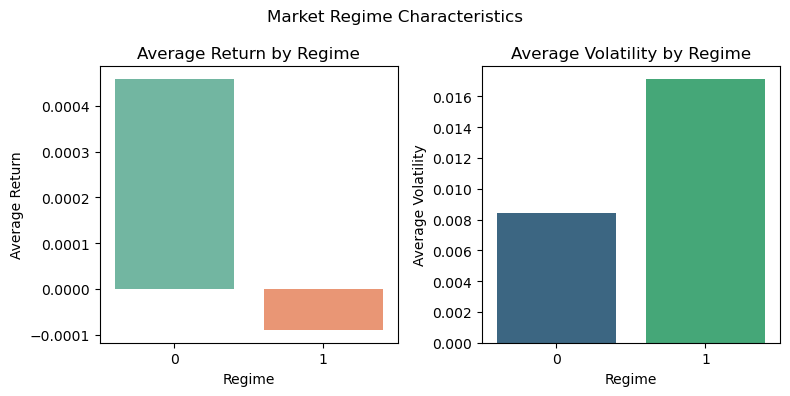

In [100]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(8,4)
)

# Average Return
sns.barplot(
    x=regime_summary.index,
    y=regime_summary['Average Return'],
    ax=axes[0],
    palette='Set2'
)

axes[0].set_title('Average Return by Regime')

# Average Volatility
sns.barplot(
    x=regime_summary.index,
    y=regime_summary['Average Volatility'],
    ax=axes[1],
    palette='viridis'
)

axes[1].set_title('Average Volatility by Regime')

plt.suptitle('Market Regime Characteristics')

plt.tight_layout()

plt.show()

In [52]:
regime_labels = {
    0: 'Normal Market',
    1: 'High Volatility'
}

### Regime Analysis and Interpretation

The K-Means clustering algorithm identified two distinct market regimes. Regime 0 represented approximately 84% of observations and was characterized by positive average returns (0.046%) and lower volatility (0.84%), suggesting normal market conditions. In contrast, Regime 1 represented approximately 16% of observations and exhibited slightly negative average returns (-0.009%) and nearly double the volatility (1.71%), indicating periods of elevated market stress and uncertainty.

Feature importance analysis further revealed that drawdown, momentum, and trend indicators were the primary drivers of regime classification, with SPY and QQQ drawdown measures contributing most significantly. This suggests that the detected regimes are influenced not only by volatility but also by sustained market declines and weakening trends.

Based on these findings, Regime 0 is labeled as the **Normal Market Regime**, while Regime 1 is labeled as the **High-Volatility Regime** and will be used in the subsequent portfolio construction and performance evaluation stages.

## 7. Regime-Based Asset Performance Analysis

Having identified two distinct market regimes, the next step is to evaluate how individual asset classes behaved within each environment. This analysis helps determine whether different portfolio allocations may be appropriate under different market conditions.

### 7.1 Average Returns by Asset and Regime

In [54]:
asset_regime_returns = (
    returns_regime
    .groupby('Regime')
    .mean()
)

asset_regime_returns

Ticker,GLD,HYG,QQQ,SPY,TLT,VNQ
Regime,,,,,,
0,0.000346,0.000227,0.000905,0.000724,0.000009,0.000540
1,0.001039,-0.000143,-0.000013,-0.000278,-0.000070,-0.001075


<Figure size 1000x600 with 0 Axes>

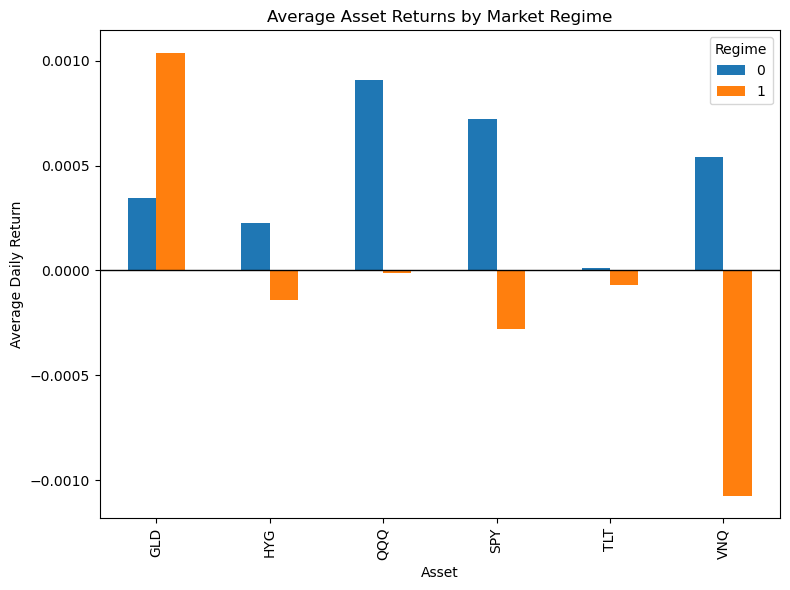

In [56]:
plt.figure(figsize=(10,6))

asset_regime_returns.T.plot(
    kind='bar',
    figsize=(8,6)
)

plt.title('Average Asset Returns by Market Regime')
plt.ylabel('Average Daily Return')
plt.xlabel('Asset')

plt.axhline(
    y=0,
    color='black',
    linewidth=1
)

plt.legend(
    title='Regime'
)

plt.tight_layout()

plt.show()

### 7.2 Asset Volatility by Regime

In [58]:
asset_regime_vol = (
    returns_regime
    .groupby('Regime')
    .std()
)

asset_regime_vol

Ticker,GLD,HYG,QQQ,SPY,TLT,VNQ
Regime,,,,,,
0,0.009937,0.003405,0.011319,0.008290,0.007954,0.009732
1,0.011908,0.010209,0.023123,0.020205,0.014347,0.022774


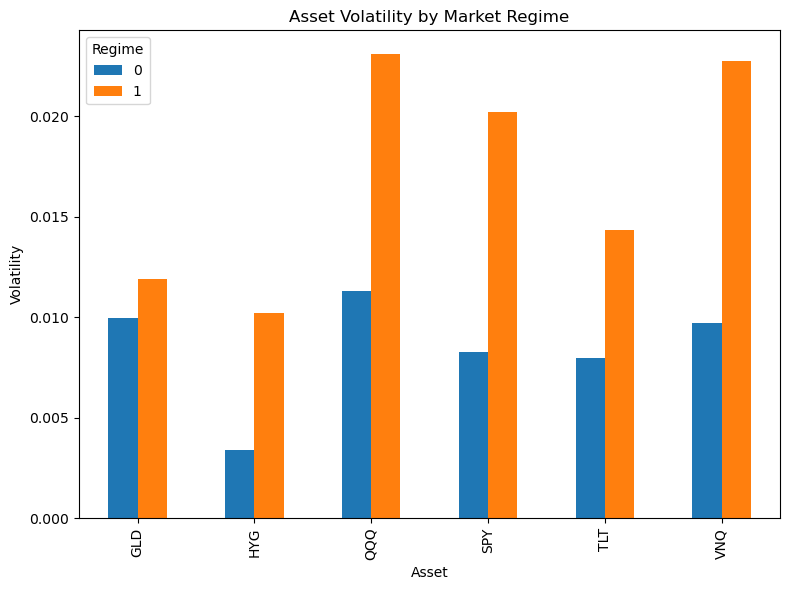

In [59]:
asset_regime_vol.T.plot(
    kind='bar',
    figsize=(8,6)
)

plt.title('Asset Volatility by Market Regime')

plt.ylabel('Volatility')

plt.xlabel('Asset')

plt.legend(
    title='Regime'
)

plt.tight_layout()

plt.show()

### 7.3 Maximum Drawdown by Regime

In [60]:
regime_drawdown = {}

for regime in [0, 1]:

    subset = returns_regime[
        returns_regime['Regime'] == regime
    ].drop(
        columns='Regime'
    )

    cumulative = (1 + subset).cumprod()

    rolling_max = cumulative.cummax()

    drawdown = (
        cumulative - rolling_max
    ) / rolling_max

    regime_drawdown[regime] = drawdown.min().mean()

regime_drawdown

{0: np.float64(-0.20105060328604976), 1: np.float64(-0.31805847219427447)}

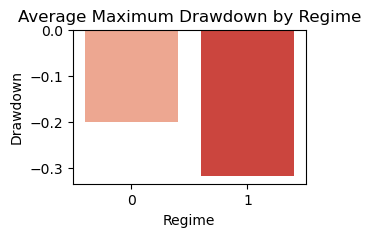

In [62]:
plt.figure(figsize=(3,2))

sns.barplot(
    x=list(regime_drawdown.keys()),
    y=list(regime_drawdown.values()),
    palette='Reds'
)

plt.title('Average Maximum Drawdown by Regime')

plt.ylabel('Drawdown')

plt.xlabel('Regime')

plt.show()

### Key Findings

- Asset performance differed significantly across the two detected market regimes.
- Regime 0 was characterized by generally positive returns and lower volatility, consistent with normal market conditions.
- Regime 1 exhibited substantially higher volatility across all asset classes, confirming its classification as a high-volatility market environment.
- GLD was the strongest performer during Regime 1, producing higher returns during periods of elevated market stress and demonstrating potential diversification benefits.
- SPY, HYG, TLT, and VNQ generated negative average returns during Regime 1, indicating weaker performance during unfavorable market conditions.
- VNQ experienced the largest deterioration in returns between the two regimes, suggesting heightened sensitivity to market stress.
- QQQ remained relatively resilient, maintaining near-flat returns despite a significant increase in volatility.
- The observed differences in risk and return characteristics across the two regimes support the use of regime-aware portfolio allocation strategies.

## 8. Regime-Aware Portfolio Construction

The regime analysis demonstrated that asset performance varies significantly across market environments. Assets that perform well during stable market conditions may underperform during periods of elevated volatility and market stress. Based on these findings, a regime-aware portfolio allocation framework is developed and compared against a traditional static portfolio.

### 8.1 Define Portfolio Weights
**Benchmark Portfolio (Static)**

In [64]:
static_weights = {
    'SPY': 0.30,
    'QQQ': 0.20,
    'TLT': 0.20,
    'GLD': 0.10,
    'VNQ': 0.10,
    'HYG': 0.10
}

#### Regime-Aware Portfolio

**Regime 0 (Normal Market)**
- SPY and QQQ produced the strongest risk-adjusted returns.
- Lower volatility environment.

In [65]:
normal_weights = {
    'SPY': 0.35,
    'QQQ': 0.30,
    'TLT': 0.10,
    'GLD': 0.05,
    'VNQ': 0.10,
    'HYG': 0.10
}

**Regime 1 (High Volatility)**
- GLD performed best
- TLT remained defensive
- VNQ suffered most
- Equities weakened

In [66]:
stress_weights = {
    'SPY': 0.15,
    'QQQ': 0.10,
    'TLT': 0.35,
    'GLD': 0.25,
    'VNQ': 0.05,
    'HYG': 0.10
}

### 8.2 Allocation Comparison Visualizations

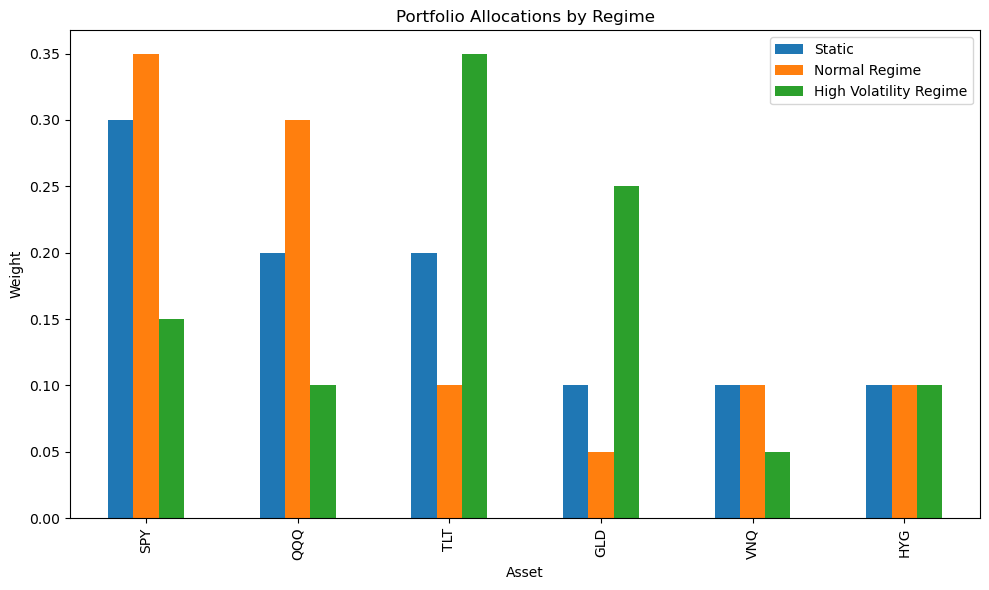

In [67]:
weights_df = pd.DataFrame({
    'Static': static_weights,
    'Normal Regime': normal_weights,
    'High Volatility Regime': stress_weights
})

weights_df.plot(
    kind='bar',
    figsize=(10,6)
)

plt.title('Portfolio Allocations by Regime')
plt.ylabel('Weight')
plt.xlabel('Asset')
plt.legend()

plt.tight_layout()
plt.show()

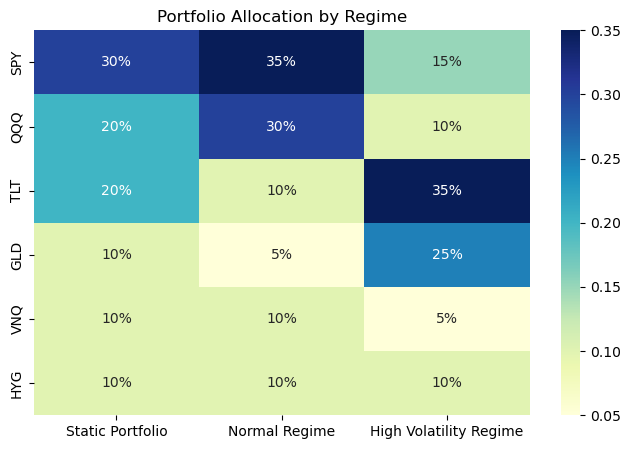

In [71]:
weights_df = pd.DataFrame({
    'Static Portfolio': static_weights,
    'Normal Regime': normal_weights,
    'High Volatility Regime': stress_weights
})

plt.figure(figsize=(8,5))

sns.heatmap(
    weights_df,
    annot=True,
    cmap='YlGnBu',
    fmt='.0%'
)

plt.title('Portfolio Allocation by Regime')

plt.show()

### Portfolio Allocation Strategy

The portfolio allocation framework was developed using insights from the regime analysis. During normal market conditions, the portfolio emphasizes growth-oriented assets such as SPY and QQQ. During high-volatility periods, allocations shift toward defensive assets including TLT and GLD, while exposure to higher-risk assets is reduced. This approach seeks to improve portfolio resilience during periods of market stress while maintaining growth exposure during stable market environments.

## 9. Portfolio Backtesting and Performance Evaluation

To evaluate whether market regime information improves portfolio allocation decisions, the performance of a regime-aware portfolio is compared against a traditional static portfolio. Portfolio returns are calculated using the identified market regimes and the corresponding allocation strategies developed in the previous section.

### 9.1 Calculate Static Portfolio Returns

In [72]:
static_returns = (
    returns_regime[['SPY','QQQ','TLT','GLD','VNQ','HYG']]
    * pd.Series(static_weights)
).sum(axis=1)

### 9.2 Calculate Regime-Aware Portfolio Returns

In [73]:
regime_returns = []

for idx, row in returns_regime.iterrows():

    current_regime = row['Regime']

    if current_regime == 0:
        weights = normal_weights
    else:
        weights = stress_weights

    portfolio_return = (
        row[['SPY','QQQ','TLT','GLD','VNQ','HYG']]
        * pd.Series(weights)
    ).sum()

    regime_returns.append(portfolio_return)

regime_portfolio_returns = pd.Series(
    regime_returns,
    index=returns_regime.index
)

### 9.3 Calculate Cumulative Performance

In [74]:
static_cumulative = (
    1 + static_returns
).cumprod()

regime_cumulative = (
    1 + regime_portfolio_returns
).cumprod()

### 9.4 Portfolio Growth Comparison

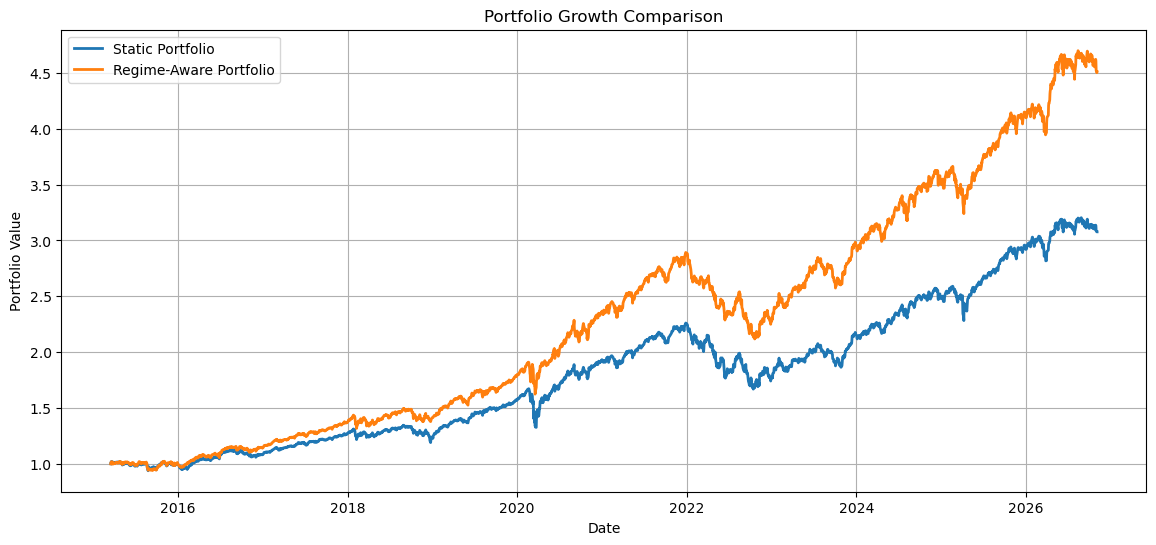

In [76]:
plt.figure(figsize=(14,6))

plt.plot(
    static_cumulative,
    label='Static Portfolio',
    linewidth=2
)

plt.plot(
    regime_cumulative,
    label='Regime-Aware Portfolio',
    linewidth=2
)

plt.title('Portfolio Growth Comparison')
plt.xlabel('Date')
plt.ylabel('Portfolio Value')

plt.legend()

plt.grid(True)

plt.show()

### 9.5 Performance Metrics

In [77]:
def portfolio_metrics(portfolio_returns):

    annual_return = (
        (1 + portfolio_returns.mean())**252
    ) - 1

    annual_volatility = (
        portfolio_returns.std()
        * np.sqrt(252)
    )

    sharpe_ratio = (
        annual_return
        / annual_volatility
    )

    cumulative = (
        1 + portfolio_returns
    ).cumprod()

    rolling_max = cumulative.cummax()

    drawdown = (
        cumulative - rolling_max
    ) / rolling_max

    max_drawdown = drawdown.min()

    return pd.Series({
        'Annual Return': annual_return,
        'Annual Volatility': annual_volatility,
        'Sharpe Ratio': sharpe_ratio,
        'Max Drawdown': max_drawdown
    })

In [78]:
performance_comparison = pd.DataFrame({
    'Static Portfolio':
        portfolio_metrics(static_returns),

    'Regime-Aware Portfolio':
        portfolio_metrics(regime_portfolio_returns)
})

performance_comparison

,Static Portfolio,Regime-Aware Portfolio
Annual Return,0.109546,0.146336
Annual Volatility,0.119925,0.117384
Sharpe Ratio,0.913454,1.246649
Max Drawdown,-0.261717,-0.267687


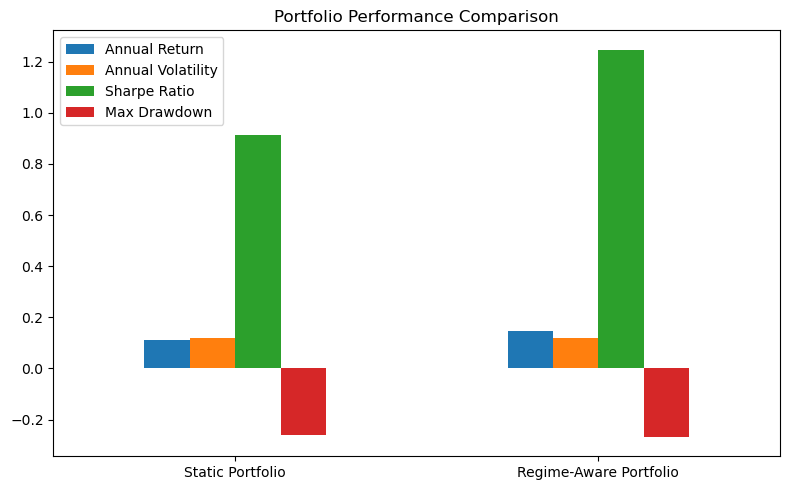

In [81]:
performance_comparison.T.plot(
    kind='bar',
    figsize=(8,5)
)

plt.title('Portfolio Performance Comparison')

plt.xticks(rotation=0)

plt.tight_layout()

plt.show()

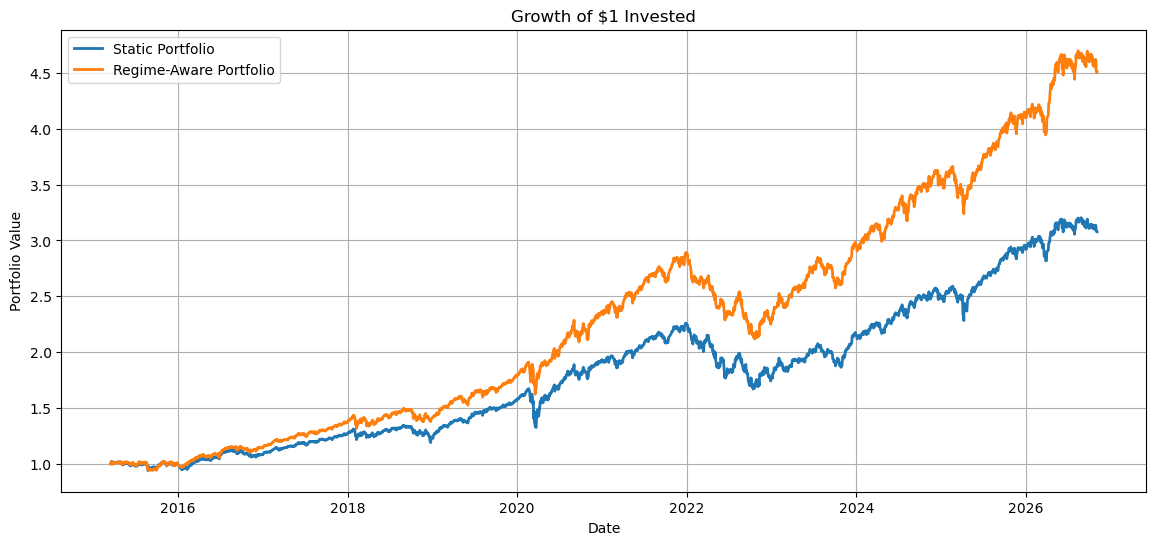

In [80]:
plt.figure(figsize=(14,6))

plt.plot(
    static_cumulative,
    label='Static Portfolio',
    linewidth=2
)

plt.plot(
    regime_cumulative,
    label='Regime-Aware Portfolio',
    linewidth=2
)

plt.title('Growth of $1 Invested')
plt.xlabel('Date')
plt.ylabel('Portfolio Value')

plt.legend()
plt.grid(True)

plt.show()

### Portfolio Performance Analysis

The regime-aware portfolio outperformed the static portfolio across most performance metrics. Annual return increased from 10.95% to 14.63%, while annual volatility decreased slightly from 11.99% to 11.74%. As a result, the Sharpe Ratio improved substantially from 0.91 to 1.25, indicating superior risk-adjusted performance. While the regime-aware portfolio experienced a marginally larger maximum drawdown, the difference was small relative to the improvement in return and risk-adjusted performance.

### Key Findings

- Annual return increased from 10.95% to 14.63%.
- Annual volatility decreased slightly from 11.99% to 11.74%.
- Sharpe Ratio improved from 0.91 to 1.25, indicating better risk-adjusted returns.
- Maximum drawdown remained similar across both portfolios.
- The regime-aware portfolio outperformed the static portfolio across most evaluation metrics.
- The results suggest that incorporating market regime information can improve portfolio allocation decisions and enhance overall portfolio performance.

## 10. Results and Discussion

The results indicate that market regime detection can provide valuable information for portfolio allocation decisions. The K-Means clustering model identified two distinct market environments characterized by meaningful differences in volatility and asset performance. Regime 0 represented stable market conditions, while Regime 1 captured periods of elevated market stress and uncertainty.

The regime-aware portfolio outperformed the static benchmark portfolio across most evaluation metrics. Annual returns increased from 10.95% to 14.63%, while annual volatility decreased slightly. As a result, the Sharpe Ratio improved substantially from 0.91 to 1.25, indicating better risk-adjusted performance.

These findings suggest that incorporating market regime information into the portfolio construction process can improve investment outcomes. By increasing exposure to growth-oriented assets during normal market conditions and shifting toward defensive assets during high-volatility periods, the regime-aware strategy was able to enhance returns while maintaining a comparable risk profile.

## 11. Limitations

This study has several limitations. First, the analysis was limited to six ETFs representing major asset classes and may not fully capture the broader investment universe. Second, the regime detection model relied on K-Means clustering, which assumes distinct cluster boundaries and may not capture all market complexities. Third, portfolio allocations were determined using simple rule-based weight adjustments rather than optimization techniques. Finally, transaction costs, taxes, and rebalancing costs were not incorporated into the backtesting framework, which may affect real-world portfolio performance.

Despite these limitations, the results provide evidence that market regime information can be incorporated into the portfolio construction process and may improve risk-adjusted investment performance.

## 12 Key Findings

- PCA reduced 36 engineered features to 11 principal components while retaining 90% of the original variance.
- K-Means clustering identified two distinct market regimes corresponding to normal and high-volatility environments.
- Regime 1 exhibited approximately double the volatility of Regime 0 and was associated with weaker asset performance.
- Gold (GLD) demonstrated the strongest performance during high-volatility periods.
- The regime-aware portfolio increased annual returns from 10.95% to 14.63%.
- The Sharpe Ratio improved from 0.91 to 1.25, indicating superior risk-adjusted performance.

## 13. Conclusion and Future Work

This project investigated whether market regime detection and machine learning-driven dynamic asset allocation can improve portfolio performance relative to a traditional static allocation strategy. Principal Component Analysis (PCA) reduced the engineered feature set from 36 features to 11 principal components while retaining 90% of the original variance. K-Means clustering identified two distinct market regimes characterized by meaningful differences in volatility and asset performance.

The regime analysis revealed that stable market environments were generally associated with higher returns and lower volatility, while high-volatility environments exhibited weaker performance and elevated risk. These differences were used to construct a regime-aware portfolio that adjusted asset allocations according to prevailing market conditions.

Backtesting results demonstrated that the regime-aware portfolio outperformed the static benchmark portfolio across most performance metrics. Annual returns increased from 10.95% to 14.63%, annual volatility decreased slightly, and the Sharpe Ratio improved from 0.91 to 1.25. These findings suggest that incorporating market regime information into the portfolio construction process can enhance risk-adjusted investment performance.

### Future Work

Future research could explore additional regime detection approaches, including Gaussian Mixture Models and Hidden Markov Models, to evaluate whether more granular market states can be identified. Further enhancements may include testing alternative numbers of regimes, incorporating macroeconomic indicators, applying portfolio optimization techniques, and accounting for transaction costs and rebalancing constraints. These extensions may provide additional insights into the effectiveness of regime-aware portfolio management strategies.

### Final Takeaway

The regime-aware portfolio achieved higher returns and superior risk-adjusted performance than the static benchmark, demonstrating the potential value of incorporating market regime information into portfolio allocation decisions.